## Team Members
1.   Zhong Ming Fu
2.   Nguyen Dang Khiem
3.   Darling Quan Zhi Ying



# Project Background:
The global football transfer market has become one of the most dynamic and financially significant aspects of modern sport. Clubs invest millions in acquiring players, often influenced by perceived talent, potential, marketability and demand. However, transfer fees and market valuations do not always align with on field performance.

Transfermarkt valuations are derived from a range of aspects instead of benched marked based on on field performance.
Attacking players, including strikers, wingers, and attacking midfielders, are particularly relevant for this study. They often command high transfer fees and attract strong market attention because of their visibility and goal contributions. At the same time, some attackers may be undervalued despite strong performance records, while others may be overvalued for reasons that extend beyond on-pitch output.

This project aims to bridge the gap between performance based ratings and economic valuations. By building a predictive model that estimates a player’s “fair value” based on their ratings and comparing it to their actual market value on transfer market, the study will classify players as undervalued, fairly valued, or overvalued. The findings can provide insights for clubs, analysts, and fans, highlighting market inefficiencies and offering a data driven perspective on player valuation.


# Problem statement:
How can we assess whether the market value of premier league’s attacking player’s is justified by their on field performance?

# Project aims:
1. Analyze Premier League players valuation using Transfermarkt data.

2. Build a model that estimates a player's fair market value from season performance features.

3. Classify players as Undervalued, Fairly Valued, or Overvalued.


# Datasets:

* Transfermarkt player profiles -> Get player profile information (e.g. Names, Nationality that we would like to see)
* Transfermarkt player market value history -> Get player market value history as our label
* Transfermarkt player performances -> Get player season performance as our features
* Transfermarkt team competition metadata -> Get team competition metadata to filter Premier League players

Source repo:
https://github.com/salimt/football-datasets


In [ ]:
from __future__ import annotations

import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, cross_validate

BASE_DIR = Path.cwd()
FOOTBALL_DATASETS_DIR = BASE_DIR / "football-datasets"
DATA_ROOT = FOOTBALL_DATASETS_DIR / "datalake" / "transfermarkt"
STITCHED_DATASET_PATH = BASE_DIR / "transfermarkt_pl_attackers_2324_2425_stitched.csv"


# Pipeline
Here is our intended pipeline for this project:

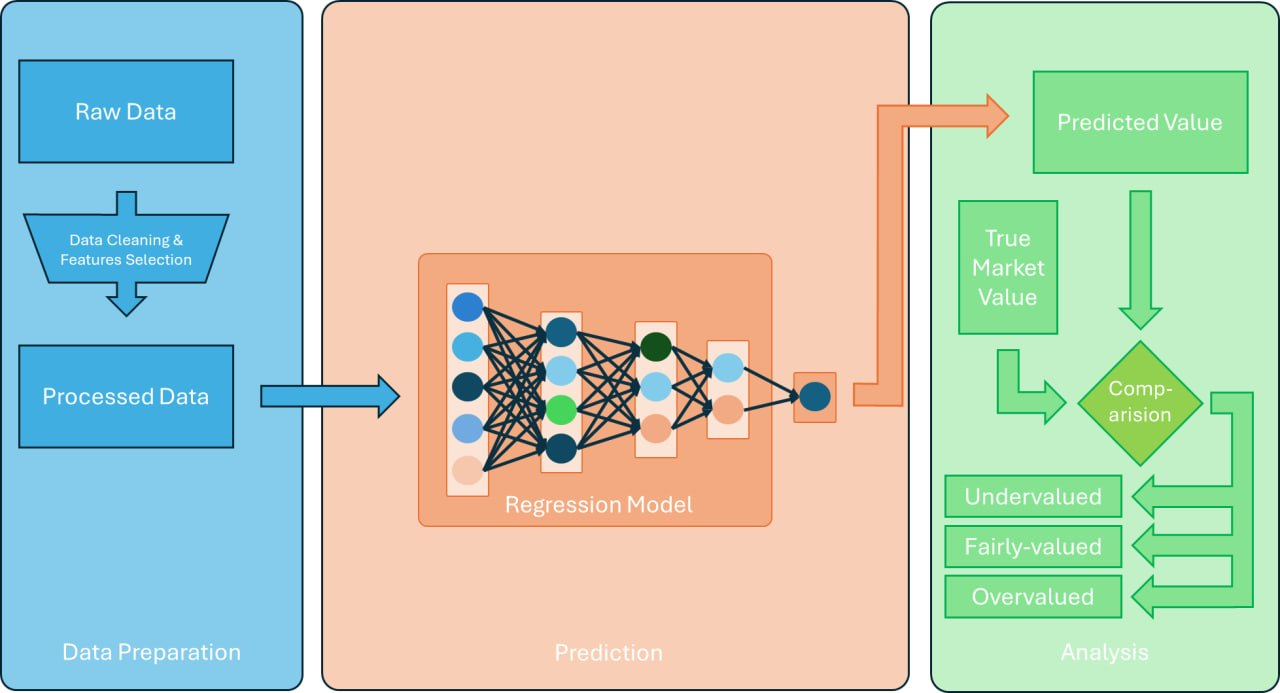

## Dependency install

Install any non-default package before running the model section.


In [ ]:
if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])

from xgboost import XGBRegressor


In [ ]:
DATASET_REPO_URL = "https://github.com/salimt/football-datasets.git"
RAW_BASE_URL = "https://media.githubusercontent.com/media/salimt/football-datasets/refs/heads/main"
LFS_DIRECT_DOWNLOADS = {
    "player_performances": (
        DATA_ROOT / "player_performances" / "player_performances.csv",
        f"{RAW_BASE_URL}/datalake/transfermarkt/player_performances/player_performances.csv",
    ),
    "transfer_history": (
        DATA_ROOT / "transfer_history" / "transfer_history.csv",
        f"{RAW_BASE_URL}/datalake/transfermarkt/transfer_history/transfer_history.csv",
    ),
}


def is_lfs_pointer(path: Path) -> bool:
    if not path.exists() or path.stat().st_size > 1024:
        return False

    with path.open("r", encoding="utf-8", errors="ignore") as handle:
        first_line = handle.readline().strip()
    return first_line == "version https://git-lfs.github.com/spec/v1"


def download_if_missing_or_pointer(path: Path, url: str) -> None:
    if path.exists() and not is_lfs_pointer(path):
        return

    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {path.name} ...")
    urlretrieve(url, path)


def sync_dataset_repo(repo_url: str, destination: Path) -> None:
    git_executable = shutil.which("git")
    if git_executable is None:
        raise FileNotFoundError(
            "Git is not installed or not on PATH. Install Git for Windows to bootstrap the dataset repository."
        )

    if destination.exists() and not (destination / ".git").exists():
        raise FileExistsError(
            f"{destination} exists but is not a Git repository. Remove it or convert it into a clean clone first."
        )

    if destination.exists():
        print(f"Using existing repository: {destination}")
    else:
        print(f"Cloning dataset repository into {destination} ...")
        clone_env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")
        subprocess.run(
            [git_executable, "clone", repo_url, str(destination)],
            check=True,
            env=clone_env,
        )

    for download_path, download_url in LFS_DIRECT_DOWNLOADS.values():
        download_if_missing_or_pointer(download_path, download_url)


if not STITCHED_DATASET_PATH.exists():
    sync_dataset_repo(DATASET_REPO_URL, FOOTBALL_DATASETS_DIR)

PLAYER_PROFILE_PATH = DATA_ROOT / "player_profiles" / "player_profiles.csv"
PLAYER_VALUE_PATH = DATA_ROOT / "player_market_value" / "player_market_value.csv"
PLAYER_PERFORMANCE_PATH = DATA_ROOT / "player_performances" / "player_performances.csv"
TEAM_COMPETITIONS_PATH = DATA_ROOT / "team_competitions_seasons" / "team_competitions_seasons.csv"

required_paths = {
    "player_profiles": PLAYER_PROFILE_PATH,
    "player_market_value": PLAYER_VALUE_PATH,
    "player_performances": PLAYER_PERFORMANCE_PATH,
    "team_competitions_seasons": TEAM_COMPETITIONS_PATH,
}

if not STITCHED_DATASET_PATH.exists():
    missing_paths = [name for name, path in required_paths.items() if not path.exists()]
    if missing_paths:
        raise FileNotFoundError(f"Missing required Transfermarkt files after sync: {missing_paths}")

setup_status = {
    "stitched_dataset_exists": STITCHED_DATASET_PATH.exists(),
    "stitched_dataset_path": str(STITCHED_DATASET_PATH),
    "dataset_repo_path": str(FOOTBALL_DATASETS_DIR),
}
setup_status


Cloning dataset repository into /content/football-datasets ...


{'stitched_dataset_exists': False,
 'stitched_dataset_path': '/content/transfermarkt_pl_attackers_2324_2425_stitched.csv',
 'dataset_repo_path': '/content/football-datasets'}

## Player Statistic Dataset

In [ ]:
def first_existing_column(df: pd.DataFrame, candidates: list[str], label: str) -> str:
    for column in candidates:
        if column in df.columns:
            return column
    raise KeyError(f"Could not find a column for {label}. Tried: {candidates}")


def parse_transfermarkt_dates(series: pd.Series) -> pd.Series:
    parsed = pd.to_datetime(series, errors="coerce")
    numeric_mask = parsed.isna() & series.notna()
    if numeric_mask.any():
        numeric_values = pd.to_numeric(series[numeric_mask], errors="coerce")
        parsed.loc[numeric_mask] = pd.to_datetime(numeric_values, unit="s", errors="coerce")
    return parsed


def extract_numeric(series: pd.Series) -> pd.Series:
    cleaned = (
        series.astype(str)
        .str.replace("'", "", regex=False)
        .str.replace(".", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.extract(r"(-?\d+)", expand=False)
    )
    return pd.to_numeric(cleaned, errors="coerce")


def normalize_text(series: pd.Series) -> pd.Series:
    return series.fillna("").astype(str).str.strip().str.lower()


SEASON_CONFIG = {
    "23/24": {"aliases": {"23/24", "2023", "2023/2024"}, "target_date": "2024-07-01", "season_start_year": 2023},
    "24/25": {"aliases": {"24/25", "2024", "2024/2025"}, "target_date": "2025-07-01", "season_start_year": 2024},
}
TARGET_COMPETITION = "premier league"


def canonicalize_season_label(series: pd.Series) -> pd.Series:
    normalized = normalize_text(series)
    canonical = pd.Series(pd.NA, index=series.index, dtype="object")
    for season_label, config in SEASON_CONFIG.items():
        canonical.loc[normalized.isin(config["aliases"])] = season_label
    return canonical


modeling_df = pd.read_csv(STITCHED_DATASET_PATH, low_memory=False) if STITCHED_DATASET_PATH.exists() else None


## Raw data load

In [ ]:
if ('tm_profile' not in globals()) or (tm_profile is None):
    tm_profile = pd.read_csv(PLAYER_PROFILE_PATH, low_memory=False)
if ('tm_values' not in globals()) or (tm_values is None):
    tm_values = pd.read_csv(PLAYER_VALUE_PATH, low_memory=False)
if ('tm_performances' not in globals()) or (tm_performances is None):
    tm_performances = pd.read_csv(PLAYER_PERFORMANCE_PATH, low_memory=False)
if ('tm_team_competitions' not in globals()) or (tm_team_competitions is None):
    tm_team_competitions = pd.read_csv(TEAM_COMPETITIONS_PATH, low_memory=False)

if ('profile_name_col' not in globals()) or (profile_name_col is None):
    profile_name_col = first_existing_column(
        tm_profile,
        ["player_name", "name", "full_name", "name_in_home_country"],
        "player name",
    )


## Position labels

Inspect the raw Transfermarkt position taxonomy here before applying the attacker-only filter.


In [ ]:
position_label_summary = {
    "main_position_labels": sorted(tm_profile["main_position"].dropna().astype(str).unique().tolist()) if "main_position" in tm_profile.columns else [],
    "position_labels": sorted(tm_profile["position"].dropna().astype(str).unique().tolist()) if "position" in tm_profile.columns else [],
}
position_label_summary


{'main_position_labels': ['Attack', 'Defender', 'Goalkeeper', 'Midfield'],
 'position_labels': ['Attack',
  'Attack - Centre-Forward',
  'Attack - Left Winger',
  'Attack - Right Winger',
  'Attack - Second Striker',
  'Defender',
  'Defender - Centre-Back',
  'Defender - Left-Back',
  'Defender - Right-Back',
  'Defender - Sweeper',
  'Goalkeeper',
  'Midfield',
  'Midfield - Attacking Midfield',
  'Midfield - Central Midfield',
  'Midfield - Defensive Midfield',
  'Midfield - Left Midfield',
  'Midfield - Right Midfield']}

## Raw performance schema exploration

The original `player_performances` table is examined before applying the Premier League and season filters so that the selected variables can be traced directly to the raw source.


In [ ]:
if ('tm_performances' not in globals()) or (tm_performances is None):
    tm_performances = pd.read_csv(PLAYER_PERFORMANCE_PATH, low_memory=False)

raw_performance_inventory = pd.DataFrame(
    {
        "column": tm_performances.columns,
        "dtype": tm_performances.dtypes.astype(str).values,
        "missing_values": tm_performances.isna().sum().values,
        "n_unique": tm_performances.nunique(dropna=False).values,
    }
)
raw_performance_inventory


,column,dtype,missing_values,n_unique
0,player_id,int64,0,88375
1,season_name,object,0,102
2,competition_id,object,0,1643
3,competition_name,object,0,1988
4,team_id,int64,0,13511
5,team_name,object,0,15411
6,nb_in_group,int64,0,51
7,nb_on_pitch,int64,0,52
8,goals,float64,138202,49
9,assists,int64,0,29


The raw performance dataset contains identifiers, competition and team context, and match contribution statistics. From this schema, the retained variables are those that most directly capture playing time, attacking output, disciplinary record, and limited defensive contribution. These measures are logically related to player performance and provide a reasonable basis for the valuation model.


## Premier League club filter


In [ ]:
teams_competition_col = first_existing_column(
    tm_team_competitions,
    ["competition_name", "season_league_league_name"],
    "team competition name",
)
teams_season_col = first_existing_column(
    tm_team_competitions,
    ["season_season", "season_id"],
    "team season",
)
teams_club_col = first_existing_column(tm_team_competitions, ["club_id"], "team club id")

team_competition_name = normalize_text(tm_team_competitions[teams_competition_col])
team_season_key = canonicalize_season_label(tm_team_competitions[teams_season_col])

pl_club_membership = tm_team_competitions.loc[
    team_competition_name.eq(TARGET_COMPETITION) & team_season_key.notna(),
    [teams_club_col],
].copy()
pl_club_membership["team_id"] = pd.to_numeric(pl_club_membership[teams_club_col], errors="coerce")
pl_club_membership["season_key"] = team_season_key.loc[pl_club_membership.index]
pl_club_membership = pl_club_membership.dropna(subset=["team_id", "season_key"]).copy()
pl_club_membership["team_id"] = pl_club_membership["team_id"].astype(int)
pl_club_membership = pl_club_membership[["team_id", "season_key"]].drop_duplicates()

club_summary = {
    "premier_league_team_season_pairs": len(pl_club_membership),
    "team_competition_matches": int(team_competition_name.eq(TARGET_COMPETITION).sum()),
    "team_season_matches": int(team_season_key.notna().sum()),
}

club_summary


{'premier_league_team_season_pairs': 40,
 'team_competition_matches': 678,
 'team_season_matches': 3474}

## Premier League player universe


In [ ]:
performance_season_col = first_existing_column(
    tm_performances,
    ["season_name", "season", "season_id"],
    "performance season",
)
performance_competition_col = first_existing_column(
    tm_performances,
    ["competition_name", "competition"],
    "performance competition",
)
performance_team_col = first_existing_column(tm_performances, ["team_id"], "performance team id")

performance_season_key = canonicalize_season_label(tm_performances[performance_season_col])
performance_competition_name = normalize_text(tm_performances[performance_competition_col])
performance_team_id = pd.to_numeric(tm_performances[performance_team_col], errors="coerce")

pl_performances = tm_performances.loc[
    performance_season_key.notna() & performance_competition_name.eq(TARGET_COMPETITION)
].copy()
pl_performances["season_key"] = performance_season_key.loc[pl_performances.index]
pl_performances["team_id"] = performance_team_id.loc[pl_performances.index]
pl_performances = pl_performances.merge(pl_club_membership, on=["team_id", "season_key"], how="inner")
pl_performances["player_id"] = pd.to_numeric(pl_performances["player_id"], errors="coerce")
pl_performances = pl_performances.dropna(subset=["player_id"]).copy()
pl_performances["player_id"] = pl_performances["player_id"].astype(int)

player_seasons = pl_performances[["player_id", "season_key"]].drop_duplicates().sort_values(["season_key", "player_id"])
profile_columns = [
    column
    for column in ["player_id", profile_name_col, "position", "main_position", "current_club_id", "current_club_name"]
    if column in tm_profile.columns
]
profile_lookup = tm_profile[profile_columns].copy().drop_duplicates("player_id")
profile_lookup = profile_lookup.rename(columns={profile_name_col: "player_name"})
profile_lookup["player_id"] = pd.to_numeric(profile_lookup["player_id"], errors="coerce")
profile_lookup = profile_lookup.dropna(subset=["player_id"]).copy()
profile_lookup["player_id"] = profile_lookup["player_id"].astype(int)
attacking_position_labels = {
    "attack",
    "attack - centre-forward",
    "attack - left winger",
    "attack - right winger",
    "attack - second striker",
    "midfield - attacking midfield",
}

performance_club_lookup = (
    pl_performances.sort_values(["season_key", "player_id", performance_team_col])
    [["player_id", "season_key", performance_team_col, "team_name"]]
    .drop_duplicates(["player_id", "season_key"])
    .rename(columns={performance_team_col: "current_club_id", "team_name": "current_club_name"})
)
performance_club_lookup["current_club_id"] = pd.to_numeric(performance_club_lookup["current_club_id"], errors="coerce")

master_players = player_seasons.merge(profile_lookup, on="player_id", how="left")
master_players = master_players.merge(performance_club_lookup, on=["player_id", "season_key"], how="left", suffixes=("", "_perf"))
master_players["season_start_year"] = master_players["season_key"].map(lambda value: SEASON_CONFIG[value]["season_start_year"])
if "current_club_id_perf" in master_players.columns:
    master_players["current_club_id"] = master_players["current_club_id"].fillna(master_players["current_club_id_perf"])
    master_players = master_players.drop(columns=["current_club_id_perf"])
if "current_club_name_perf" in master_players.columns:
    master_players["current_club_name"] = master_players["current_club_name"].fillna(master_players["current_club_name_perf"])
    master_players = master_players.drop(columns=["current_club_name_perf"])
if "player_name" not in master_players.columns:
    master_players["player_name"] = master_players["player_id"].astype(str)
position_label = normalize_text(master_players["position"]) if "position" in master_players.columns else pd.Series("", index=master_players.index)
main_position_label = normalize_text(master_players["main_position"]) if "main_position" in master_players.columns else pd.Series("", index=master_players.index)
attacking_mask = main_position_label.eq("attack") | position_label.isin(attacking_position_labels)
master_players = master_players.loc[attacking_mask].copy()
pl_performances = pl_performances.merge(master_players[["player_id", "season_key"]], on=["player_id", "season_key"], how="inner")

universe_summary = {
    "performance_rows": len(pl_performances),
    "player_seasons_in_universe": len(master_players),
    "unique_players_in_universe": int(master_players["player_id"].nunique()),
    "performance_competition_matches": int(performance_competition_name.eq(TARGET_COMPETITION).sum()),
    "performance_season_matches": int(performance_season_key.notna().sum()),
    "performance_team_matches": int(performance_team_id.notna().sum()),
}

universe_summary


{'performance_rows': 480,
 'player_seasons_in_universe': 465,
 'unique_players_in_universe': 328,
 'performance_competition_matches': 18131,
 'performance_season_matches': 267208,
 'performance_team_matches': 1878719}

## Raw performance EDA

This exploratory analysis is conducted on the raw Transfermarkt performance table after restricting the data to the target competition and season. This places the data inspection stage before player-level feature engineering and valuation modelling.


In [ ]:
raw_excluded_columns = {
    "player_id",
    "team_id",
    "competition_id",
    "competition_url",
    "competition_name",
    "team_url",
    "team_name",
    "season",
}
raw_numeric_columns = [
    column
    for column in pl_performances.columns
    if column not in raw_excluded_columns
    and (
        pd.api.types.is_numeric_dtype(pl_performances[column])
        or pd.api.types.is_object_dtype(pl_performances[column])
    )
]
pl_raw_eda = pl_performances[raw_numeric_columns].copy()
for column in raw_numeric_columns:
    if pd.api.types.is_object_dtype(pl_raw_eda[column]):
        pl_raw_eda[column] = extract_numeric(pl_raw_eda[column])
    else:
        pl_raw_eda[column] = pd.to_numeric(pl_raw_eda[column], errors="coerce")

raw_eda_columns = [column for column in pl_raw_eda.columns if pl_raw_eda[column].notna().sum() > 0]
pl_raw_eda = pl_raw_eda[raw_eda_columns].copy()
if pl_raw_eda.empty:
    raise ValueError("pl_raw_eda is empty. Re-run the Premier League filtering cells before this EDA step.")

raw_performance_summary = pl_raw_eda.describe().T
raw_performance_summary["missing_values"] = pl_raw_eda.isna().sum().values
raw_performance_summary["n_unique"] = pl_raw_eda.nunique(dropna=False).values

raw_performance_summary


,count,mean,std,min,25%,50%,75%,max,missing_values,n_unique
season_name,480.0,23.485417,0.500309,23.0,23.0,23.0,24.00,24.0,0,2
nb_in_group,480.0,21.052083,12.947598,1.0,8.0,23.0,33.00,38.0,0,38
nb_on_pitch,480.0,17.450000,13.402458,0.0,3.0,17.5,31.00,38.0,0,39
goals,480.0,3.483333,4.895541,0.0,0.0,1.0,5.25,29.0,0,26
assists,480.0,2.241667,3.182011,0.0,0.0,1.0,3.00,18.0,0,15
own_goals,480.0,0.004167,0.064482,0.0,0.0,0.0,0.00,1.0,0,2
subed_in,480.0,6.452083,5.775352,0.0,1.0,5.0,10.00,26.0,0,25
subed_out,480.0,6.495833,6.846054,0.0,0.0,4.0,11.25,29.0,0,28
yellow_cards,480.0,1.843750,2.355326,0.0,0.0,1.0,3.00,12.0,0,13
second_yellow_cards,480.0,0.022917,0.163137,0.0,0.0,0.0,0.00,2.0,0,3


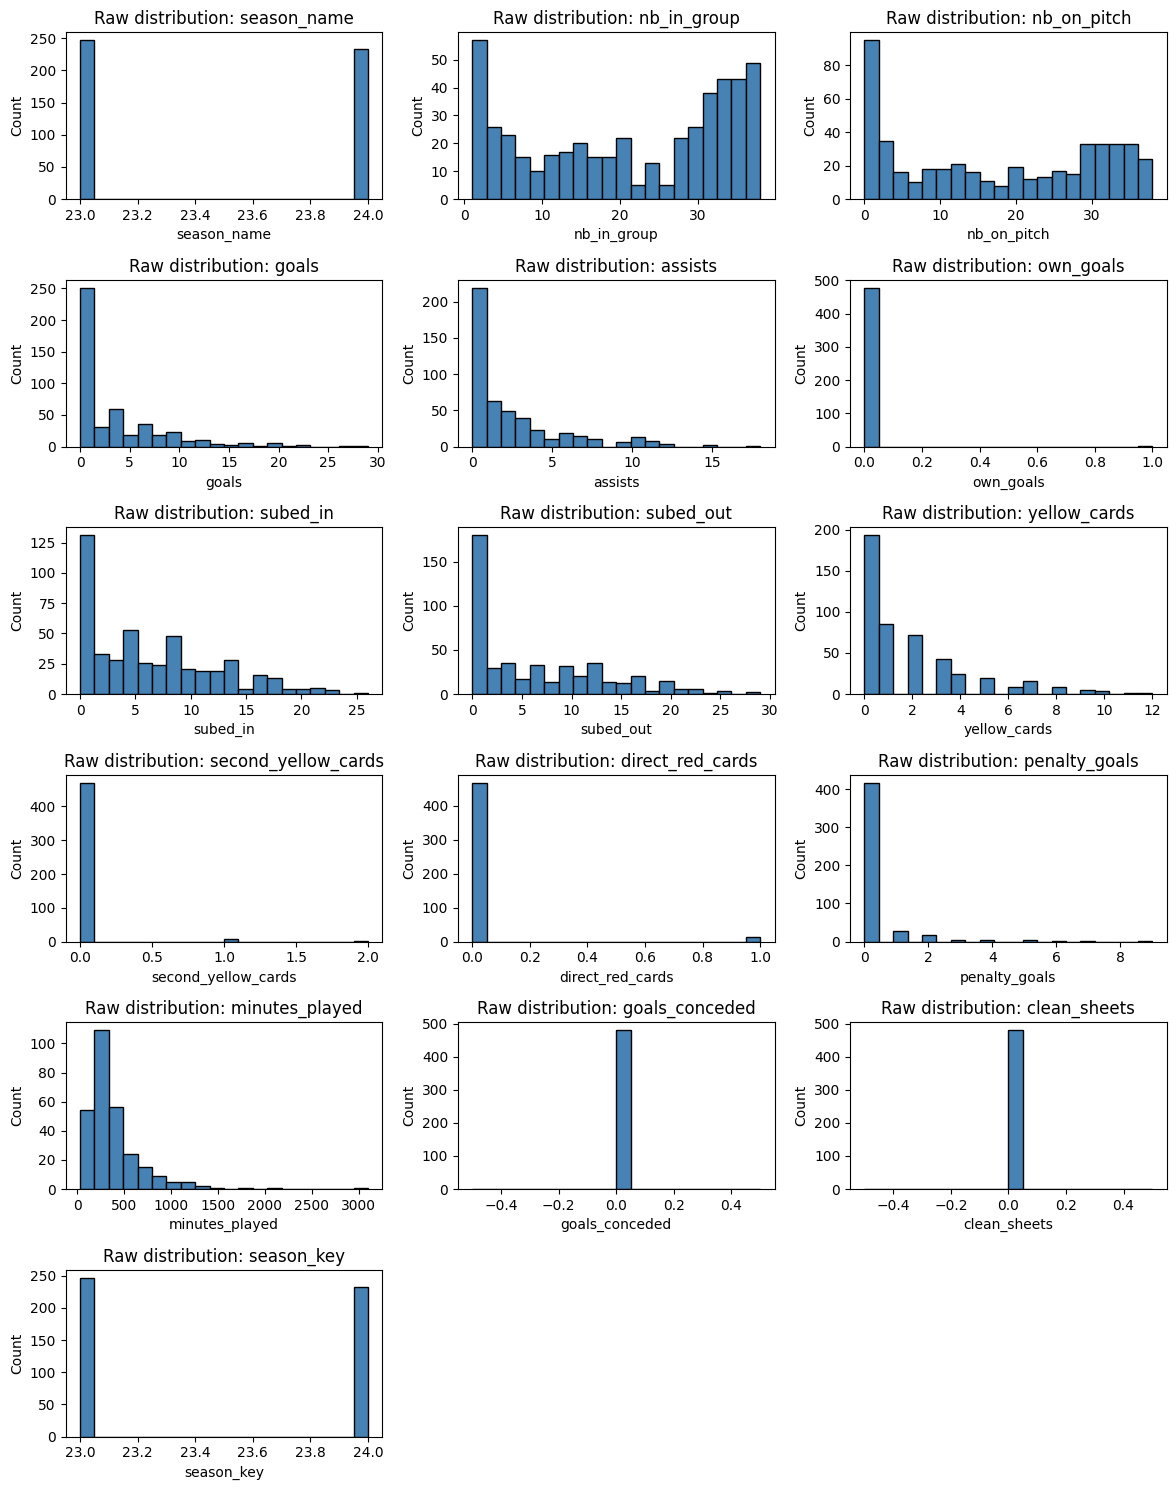

In [ ]:
raw_plot_columns = pl_raw_eda.columns.tolist()
n_cols = 3
n_rows = int(np.ceil(len(raw_plot_columns) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.5 * n_rows))
axes = np.atleast_1d(axes).flatten()
for ax, column in zip(axes, raw_plot_columns):
    ax.hist(pl_raw_eda[column].dropna(), bins=20, color="steelblue", edgecolor="black")
    ax.set_title(f"Raw distribution: {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")
for ax in axes[len(raw_plot_columns):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


The raw Premier League 2024/25 subset shows which numeric performance fields are available, how much variation they contain, and how complete they are after the basic league and season restriction. This provides the basis for selecting the performance variables used in the later feature engineering step.


## Player Value Dataset

In [ ]:
if modeling_df is None:
    value_date_col = first_existing_column(tm_values, ["date_unix", "date", "snapshot_date"], "market value date")
    value_amount_col = first_existing_column(tm_values, ["value", "market_value", "player_market_value"], "market value")
    tm_values["player_id"] = pd.to_numeric(tm_values["player_id"], errors="coerce")
    tm_values["snapshot_date"] = parse_transfermarkt_dates(tm_values[value_date_col])

    def closest_value_snapshot(
        values_df: pd.DataFrame,
        player_season_df: pd.DataFrame,
        max_diff_days: int = 90,
    ) -> pd.DataFrame:
        snapshots = []

        # Obtain snapshots from each season
        for season_key, config in SEASON_CONFIG.items():
            season_players = player_season_df.loc[player_season_df["season_key"].eq(season_key), ["player_id", "season_key"]]
            target_ts = pd.Timestamp(config["target_date"])
            snapshot = values_df.loc[values_df["player_id"].isin(season_players["player_id"])].copy()
            snapshot = snapshot.dropna(subset=["player_id", "snapshot_date", value_amount_col])
            snapshot["diff_days"] = (snapshot["snapshot_date"] - target_ts).abs().dt.days
            snapshot = (
                snapshot.sort_values(["player_id", "diff_days", "snapshot_date"])
                .groupby("player_id", as_index=False)
                .first()
            )
            snapshot = snapshot.loc[
                snapshot["diff_days"] <= max_diff_days,
                ["player_id", "snapshot_date", value_amount_col, "diff_days"],
            ].copy()
            snapshot["season_key"] = season_key
            snapshot = snapshot.rename(
                columns={
                    "snapshot_date": "market_value_snapshot_date",
                    value_amount_col: "market_value",
                    "diff_days": "market_value_diff_days",
                }
            )
            snapshots.append(snapshot)
        return pd.concat(snapshots, ignore_index=True)

    value_snapshots = closest_value_snapshot(tm_values, master_players[["player_id", "season_key"]].drop_duplicates())
    snapshot_summary = value_snapshots.groupby("season_key").size().to_dict()
else:
    snapshot_summary = modeling_df.groupby("season_key").size().to_dict()

snapshot_summary


{'23/24': 199, '24/25': 211}

All of the availaible statistic we can use:

In [ ]:
player_preview = modeling_df.head() if modeling_df is not None else master_players.head()
player_preview


,player_id,season_key,player_name,position,main_position,current_club_id,current_club_name,season_start_year
11,42460,23/24,Ivan Perišić (42460),Attack - Left Winger,Attack,383,PSV Eindhoven,2023
12,43530,23/24,Adam Lallana (43530),Midfield - Attacking Midfield,Midfield,123,Retired,2023
15,51152,23/24,Aleksandar Mitrović (51152),Attack - Centre-Forward,Attack,3229,Al-Rayyan SC,2023
21,52769,23/24,Willian (52769),Attack - Left Winger,Attack,210,Grêmio Foot-Ball Porto Alegrense,2023
22,53360,23/24,Jay Rodríguez (53360),Attack - Centre-Forward,Attack,1112,Wrexham AFC,2023


## Data preparation

* Use all available 23/24 and 24/25 Premier League player performance rows.
* Build a stitched player-season dataset by aggregating season statistics and joining the closest Transfermarkt market value snapshot near each season-end anchor date.
* Restrict the player pool to attacking roles: forwards, wingers, second strikers, and attacking midfielders.


## Season feature engineering


In [ ]:
if modeling_df is None:
    feature_aliases = {
        "minutes_played": ["minutes_played"],
        "appearances": ["nb_in_group", "appearances", "matches"],
        "goals": ["goals"],
        "assists": ["assists"],
        "yellow_cards": ["yellow_cards"],
        "red_cards": ["direct_red_cards"],
        "penalty_goals": ["penalty_goals"],
        "clean_sheets": ["clean_sheets"],
        "goals_conceded": ["goals_conceded"],
    }

    resolved_features = {}
    for canonical_name, candidates in feature_aliases.items():
        resolved_column = first_existing_column(pl_performances, candidates, canonical_name)
        resolved_features[canonical_name] = resolved_column

    performance_columns = ["player_id", "season_key", *resolved_features.values()]
    season_features = pl_performances[performance_columns].copy()
    for column in performance_columns:
        if column not in {"player_id", "season_key"}:
            season_features[column] = extract_numeric(season_features[column]).fillna(0)

    season_features = season_features.groupby(["player_id", "season_key"], as_index=False).sum(numeric_only=True)
    season_features = season_features.rename(columns={source: target for target, source in resolved_features.items()})

    per_90_base_columns = [
        column for column in season_features.columns if column not in {"player_id", "season_key", "minutes_played", "appearances"}
    ]
    valid_minutes = season_features["minutes_played"].replace(0, np.nan)
    for column in per_90_base_columns:
        season_features[f"{column}_per_90"] = season_features[column] / valid_minutes * 90

    feature_table = master_players.merge(season_features, on=["player_id", "season_key"], how="inner")
    numeric_columns = feature_table.select_dtypes(include=[np.number]).columns.tolist()
    for column in numeric_columns:
        if column != "player_id":
            feature_table[column] = feature_table[column].fillna(0)
    feature_preview = feature_table.shape
else:
    feature_preview = modeling_df.shape

feature_preview


(465, 24)

In [ ]:
feature_preview_df = modeling_df.head() if modeling_df is not None else feature_table.head()
feature_preview_df


,player_id,season_key,player_name,position,main_position,current_club_id,current_club_name,season_start_year,minutes_played,appearances,...,penalty_goals,clean_sheets,goals_conceded,goals_per_90,assists_per_90,yellow_cards_per_90,red_cards_per_90,penalty_goals_per_90,clean_sheets_per_90,goals_conceded_per_90
0,42460,23/24,Ivan Perišić (42460),Attack - Left Winger,Attack,383,PSV Eindhoven,2023,0.0,5,...,0,0,0,0.000000,0.000000,0.00000,0.0,0.000000,0.0,0.0
1,43530,23/24,Adam Lallana (43530),Midfield - Attacking Midfield,Midfield,123,Retired,2023,0.0,33,...,0,0,0,0.000000,0.000000,0.00000,0.0,0.000000,0.0,0.0
2,51152,23/24,Aleksandar Mitrović (51152),Attack - Centre-Forward,Attack,3229,Al-Rayyan SC,2023,0.0,1,...,0,0,0,0.000000,0.000000,0.00000,0.0,0.000000,0.0,0.0
3,52769,23/24,Willian (52769),Attack - Left Winger,Attack,210,Grêmio Foot-Ball Porto Alegrense,2023,5140.0,33,...,2,0,0,0.700389,0.035019,0.01751,0.0,0.035019,0.0,0.0
4,53360,23/24,Jay Rodríguez (53360),Attack - Centre-Forward,Attack,1112,Wrexham AFC,2023,4070.0,35,...,1,0,0,0.442260,0.022113,0.00000,0.0,0.022113,0.0,0.0


##Data Enriching

|New aggregated variable | measurement | Type
| --- | --- | --- |
|`goal_involvement` | Direct contribution to goals | int|
|`goal_involvement_per_90` | Average goal involvement per match | float|
|`non_penalty_goals` | Open play scoring ability | int|
|`attacking_efficiency` | Ratio of goal contributions | float|
|`discipline_ratio` | Ratio of cards issued per goal contribution | float|


In [ ]:
# Data Enriching
# Creating more performance metrics using agregation
if modeling_df is None:
    modeling_df = feature_table.merge(value_snapshots, on=["player_id", "season_key"], how="inner").copy()


  modeling_df["goal_involvement"] = modeling_df["goals"] + modeling_df["assists"]
  modeling_df["goal_involvement_per_90"] = modeling_df["goals_per_90"] + modeling_df["assists_per_90"]
  modeling_df["non_penalty_goals"] = modeling_df["goals"] - modeling_df["penalty_goals"]
  modeling_df["attacking_efficiency"] = modeling_df["goal_involvement"] / modeling_df["minutes_played"]
  modeling_df["discipline_ratio"] = modeling_df["goal_involvement"] / (modeling_df["yellow_cards"] + modeling_df["red_cards"])

modeling_df[["player_id","player_name","position","goal_involvement","goal_involvement_per_90","non_penalty_goals","attacking_efficiency","discipline_ratio"]]

,player_id,player_name,position,goal_involvement,goal_involvement_per_90,non_penalty_goals,attacking_efficiency,discipline_ratio
0,42460,Ivan Perišić (42460),Attack - Left Winger,1,0.000000,0,inf,0.5
1,43530,Adam Lallana (43530),Midfield - Attacking Midfield,1,0.000000,0,inf,0.5
2,51152,Aleksandar Mitrović (51152),Attack - Centre-Forward,0,0.000000,0,NaN,NaN
3,52769,Willian (52769),Attack - Left Winger,42,0.735409,38,0.008171,42.0
4,53360,Jay Rodríguez (53360),Attack - Centre-Forward,21,0.464373,19,0.005160,inf
...,...,...,...,...,...,...,...,...
405,1047256,Asher Agbinone (1047256),Attack - Left Winger,0,0.000000,0,NaN,NaN
406,1086375,Gustavo Nunes (1086375),Attack - Left Winger,0,0.000000,0,NaN,NaN
407,1089802,Remy Rees-Dottin (1089802),Attack - Centre-Forward,0,0.000000,0,NaN,NaN
408,1230661,Mateus Mané (1230661),Attack - Centre-Forward,0,0.000000,0,NaN,NaN


## Selected performance features

Based on the raw performance EDA and football interpretation, the selected variables focus on playing time and attacking production, discipline. We then convert those raw columns into a player-level feature table and add per-90 versions so players with different minutes played can still be compared on a common rate basis.


| Feature | Role |
| --- | --- |
| `minutes_played` | playing time |
| `appearances` | availability |
| `goals` | attacking output |
| `assists` | chance creation |
| `yellow_cards` | discipline |
| `red_cards` | discipline |
| `penalty_goals` | set-piece scoring |
| `goals_per_90` | rate-normalized attacking output |
| `assists_per_90` | rate-normalized chance creation |
| `yellow_cards_per_90` | rate-normalized discipline |
| `red_cards_per_90` | rate-normalized discipline |
| `penalty_goals_per_90` | rate-normalized set-piece scoring |
|`goal_involvement` | Aggregated goal contributions|
|`goal_involvement_per_90` | Aggregated goal contributions per 90|
|`non_penalty_goals` | Open play scoring ability|
|`attacking_efficiency` | Ratio of goal contribution|
|`discipline_ratio` | Ratio of cards issued per goal contribution|

## Stitched dataset


In [ ]:
if modeling_df is None:
    modeling_df = feature_table.merge(value_snapshots, on=["player_id", "season_key"], how="inner").copy()
    modeling_df.to_csv(STITCHED_DATASET_PATH, index=False)

# Remove non model training columns
excluded_columns = {
    "player_id",
    "season_key",
    "player_name",
    "position",
    "main_position",
    "current_club_id",
    "current_club_name",
    "market_value",
    "market_value_snapshot_date",
    "market_value_diff_days",
    "clean_sheets",
    "goals_conceded",
    "season_start_year",
    "clean_sheets_per_90",
    "goals_conceded_per_90"
}
feature_columns = [
    column
    for column in modeling_df.columns
    if column not in excluded_columns and pd.api.types.is_numeric_dtype(modeling_df[column])
]

X = modeling_df[feature_columns].astype(float)
y = np.log1p(modeling_df["market_value"].astype(float))
cv = KFold(n_splits=5, shuffle=True, random_state=42)

data_prep_summary = {
    "stitched_dataset_path": str(STITCHED_DATASET_PATH),
    "stitched_rows": len(modeling_df),
    "n_features": len(feature_columns),
    "cv_folds": cv.get_n_splits(),
    "target_column": "market_value",
}
data_prep_summary


{'stitched_dataset_path': '/content/transfermarkt_pl_attackers_2324_2425_stitched.csv',
 'stitched_rows': 410,
 'n_features': 17,
 'cv_folds': 5,
 'target_column': 'market_value'}

We use log(y) as the target label because we are interested in relative comparisons rather than absolute differences. A difference in log(y) corresponds directly to a ratio in the original scale. This makes model predictions more interpretable when the quantity of interest is "how many times larger" rather than "how much larger."

## Stitched dataset summary

The table below reports the total stitched row count, unique player count, and a season-by-season breakdown so the combined 2023/24 and 2024/25 coverage is explicit.


In [ ]:
stitched_dataset_summary = {
    "rows": len(modeling_df),
    "unique_players": int(modeling_df["player_id"].nunique()),
    "player_seasons": int(modeling_df[["player_id", "season_key"]].drop_duplicates().shape[0]),
}
season_breakdown = (
    modeling_df.groupby("season_key")
    .agg(rows=("player_id", "size"), unique_players=("player_id", "nunique"))
    .reset_index()
    .sort_values("season_key")
)
stitched_dataset_summary, season_breakdown


({'rows': 410, 'unique_players': 284, 'player_seasons': 410},
   season_key  rows  unique_players
 0      23/24   199             199
 1      24/25   211             211)

## Data cleaning

The model matrix is cleaned explicitly here by replacing infinite values, filling missing values, and checking that no `NaN` or `Inf` values remain before model fitting.


In [ ]:
X = X.replace([np.inf, -np.inf], np.nan)
cleaning_summary = {
    "nan_before_fill": int(X.isna().sum().sum()),
    "inf_before_fill": int(np.isinf(X.to_numpy()).sum()),
}
X = X.fillna(0.0)
post_cleaning_check = {
    "nan_after_fill": int(X.isna().sum().sum()),
    "inf_after_fill": int(np.isinf(X.to_numpy()).sum()),
}
cleaning_summary, post_cleaning_check


({'nan_before_fill': 255, 'inf_before_fill': 0},
 {'nan_after_fill': 0, 'inf_after_fill': 0})

## Correlation analysis


Analyse the correlation between the features and market vaalue

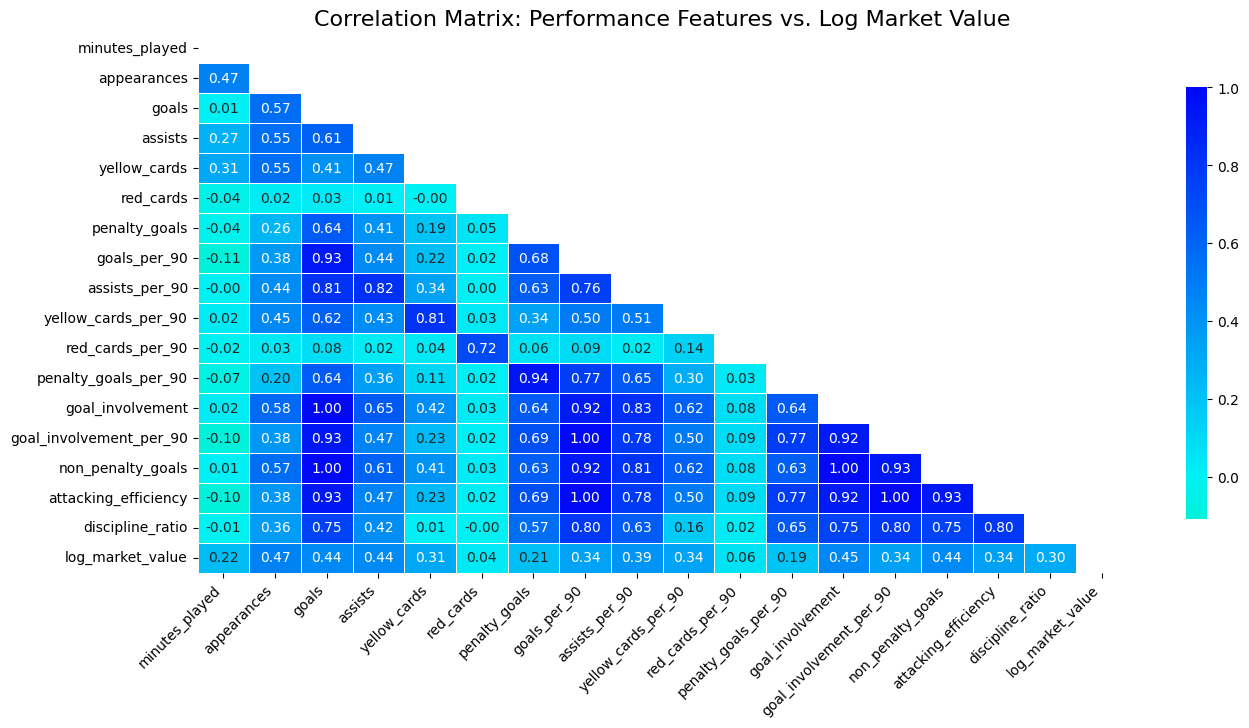

In [ ]:
#We use the log-transformed 'y' because the model was trained on it
cor_data = X.copy()
cor_data['log_market_value'] = y

corr_matrix = cor_data.corr()

plt.figure(figsize=(15,7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Mask the upper triangle for better readability

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap= sns.blend_palette(["#10F500","#00F1F5","#0008F5"], as_cmap=True),
    center=0,
    mask=mask,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix: Performance Features vs. Log Market Value', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.show()

## Model fitting and cross-validation

The valuation model is trained with 5-fold cross-validation. Out-of-fold predictions are used to estimate validation performance on the full dataset, after which the model is refit on all rows to produce the final fair-value estimates.


In [ ]:
base_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
)

cv_results = cross_validate(
    base_model,
    X,
    y,
    cv=cv,
    scoring={
        "mae_log": "neg_mean_absolute_error",
        "rmse_log": "neg_root_mean_squared_error",
        "r2": "r2",
    },
)
oof_log_predictions = cross_val_predict(base_model, X, y, cv=cv, method="predict")

fold_metrics = pd.DataFrame(
    {
        "fold": np.arange(1, cv.get_n_splits() + 1),
        "mae_log_value": -cv_results["test_mae_log"],
        "rmse_log_value": -cv_results["test_rmse_log"],
        "r2_log_value": cv_results["test_r2"],
    }
)

actual_market_values = np.expm1(y)
oof_market_value_predictions = np.maximum(0, np.expm1(oof_log_predictions))
modeling_df["cv_predicted_market_value"] = oof_market_value_predictions
modeling_df["cv_residual_market_value"] = actual_market_values - oof_market_value_predictions
modeling_df["cv_abs_pct_error"] = np.abs(
    modeling_df["cv_residual_market_value"]
    / np.where(actual_market_values == 0, np.nan, actual_market_values)
)

final_model = clone(base_model)
final_model.fit(X, y)
modeling_df["predicted_market_value"] = np.maximum(0, np.expm1(final_model.predict(X)))
modeling_df["valuation_gap"] = modeling_df["market_value"] - modeling_df["predicted_market_value"]
modeling_df["valuation_gap_pct"] = modeling_df["valuation_gap"] / modeling_df["predicted_market_value"].replace(0, np.nan)

# Ratio-driven valuation analysis (actual value vs model fair value)
modeling_df["value_to_prediction_ratio"] = modeling_df["market_value"] / modeling_df["predicted_market_value"].replace(0, np.nan)
RATIO_FAIR_LOWER = 0.85
RATIO_FAIR_UPPER = 1.15
modeling_df["valuation_status"] = np.select(
    [
        modeling_df["value_to_prediction_ratio"] > RATIO_FAIR_UPPER,
        modeling_df["value_to_prediction_ratio"] < RATIO_FAIR_LOWER,
    ],
    ["Overvalued", "Undervalued"],
    default="Fairly Valued",
)

RATIO_BINS = [0, 0.70, 0.85, 1.15, 1.30, np.inf]
RATIO_LABELS = ["<=0.70", "0.70-0.85", "0.85-1.15 (Fair)", "1.15-1.30", ">1.30"]
modeling_df["valuation_ratio_range"] = pd.cut(
    modeling_df["value_to_prediction_ratio"],
    bins=RATIO_BINS,
    labels=RATIO_LABELS,
    include_lowest=True,
)

model_summary = {
    "model_type": "XGBRegressor",
    "cv_folds": cv.get_n_splits(),
    "mean_mae_log_value": float(fold_metrics["mae_log_value"].mean()),
    "std_mae_log_value": float(fold_metrics["mae_log_value"].std(ddof=1)),
    "mean_rmse_log_value": float(fold_metrics["rmse_log_value"].mean()),
    "std_rmse_log_value": float(fold_metrics["rmse_log_value"].std(ddof=1)),
    "mean_r2_log_value": float(fold_metrics["r2_log_value"].mean()),
    "std_r2_log_value": float(fold_metrics["r2_log_value"].std(ddof=1)),
    "oof_mae_value_millions": float(mean_absolute_error(actual_market_values, oof_market_value_predictions) / 1_000_000),
    "oof_rmse_value_millions": float(np.sqrt(mean_squared_error(actual_market_values, oof_market_value_predictions)) / 1_000_000),
    "oof_r2_value": float(r2_score(actual_market_values, oof_market_value_predictions)),
    "stitched_rows": len(modeling_df),
    "n_features": len(feature_columns),
}
model_summary


{'model_type': 'XGBRegressor',
 'cv_folds': 5,
 'mean_mae_log_value': 1.0227859986260293,
 'std_mae_log_value': 0.16955478240420263,
 'mean_rmse_log_value': 1.8339344820725003,
 'std_rmse_log_value': 0.7992804250372149,
 'mean_r2_log_value': 0.009244500795439725,
 'std_r2_log_value': 0.39921251410212605,
 'oof_mae_value_millions': 13.60670420415765,
 'oof_rmse_value_millions': 22.72680823386033,
 'oof_r2_value': 0.26674770933168535,
 'stitched_rows': 410,
 'n_features': 17}

In [ ]:
fold_metrics


,fold,mae_log_value,rmse_log_value,r2_log_value
0,1,0.979804,1.244025,0.446466
1,2,0.840450,1.368526,-0.289435
2,3,1.184858,2.669990,0.147087
3,4,0.893732,1.147396,0.258296
4,5,1.215086,2.739735,-0.516191


The mean fold metrics summarize expected validation accuracy, while the standard deviations indicate how stable the model is across different splits. Lower fold-to-fold variation supports a more reliable model; the out-of-fold metrics in `model_summary` are the main validation statistics for reporting.


### Valuation Ratio Range Justification

To classify players as undervalued, fairly valued, or overvalued, this study uses the ratio:

$$\text{value to prediction ratio}=\frac{\text{actual market value}}{\text{model-predicted fair value}}$$

We define **Fairly Valued** as a ratio between **0.85 and 1.15**, **Undervalued** below **0.85**, and **Overvalued** above **1.15**.

This range is a practical modeling choice: football market values are noisy, and moderate differences between predicted and observed values can come from timing effects, short-term sentiment, negotiation dynamics, and normal model error. A +/-15% band is therefore used as a tolerance zone where predicted and observed values are considered broadly aligned. Values outside this band are treated as stronger signals of potential mispricing, not absolute proof of incorrect market pricing.


### Displaying the top 10 players with highest predicted market values

In [ ]:
from IPython.display import display

cols_to_show = [
    "player_id",
    "player_name",
    "season_key",
    "market_value",
    "predicted_market_value",
    "value_to_prediction_ratio",
    "valuation_gap_pct",
    "valuation_status",
]

display_df = (
    modeling_df[modeling_df["season_key"] == "24/25"][cols_to_show]
    .sort_values("predicted_market_value", ascending=False)
    .head(10)
)

display(display_df.style.format({
    "market_value": "€{:,.0f}",
    "predicted_market_value": "€{:,.0f}",
    "value_to_prediction_ratio": "{:.2f}x",
    "valuation_gap_pct": "{:.2f}"
}))

,player_id,player_name,season_key,market_value,predicted_market_value,value_to_prediction_ratio,valuation_gap_pct,valuation_status
264,349066,Alexander Isak (349066),24/25,"€120,000,000","€112,032,528",1.07x,0.07,Fairly Valued
282,418560,Erling Haaland (418560),24/25,"€180,000,000","€111,896,072",1.61x,0.61,Overvalued
289,433177,Bukayo Saka (433177),24/25,"€150,000,000","€94,171,320",1.59x,0.59,Overvalued
324,568177,Cole Palmer (568177),24/25,"€120,000,000","€74,902,128",1.60x,0.60,Overvalued
304,503733,Anthony Gordon (503733),24/25,"€65,000,000","€63,307,376",1.03x,0.03,Fairly Valued
216,148455,Mohamed Salah (148455),24/25,"€50,000,000","€62,845,512",0.80x,-0.20,Undervalued
229,240306,Bruno Fernandes (240306),24/25,"€50,000,000","€60,175,220",0.83x,-0.17,Undervalued
280,413039,Bryan Mbeumo (413039),24/25,"€55,000,000","€59,258,676",0.93x,-0.07,Fairly Valued
301,480692,Luis Díaz (480692),24/25,"€70,000,000","€58,168,068",1.20x,0.20,Overvalued
305,503743,Morgan Rogers (503743),24/25,"€55,000,000","€57,823,384",0.95x,-0.05,Fairly Valued


## Summary Analysis of Results

/tmp/ipykernel_4350/4141168927.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=modeling_df, x="valuation_status", order=status_order,


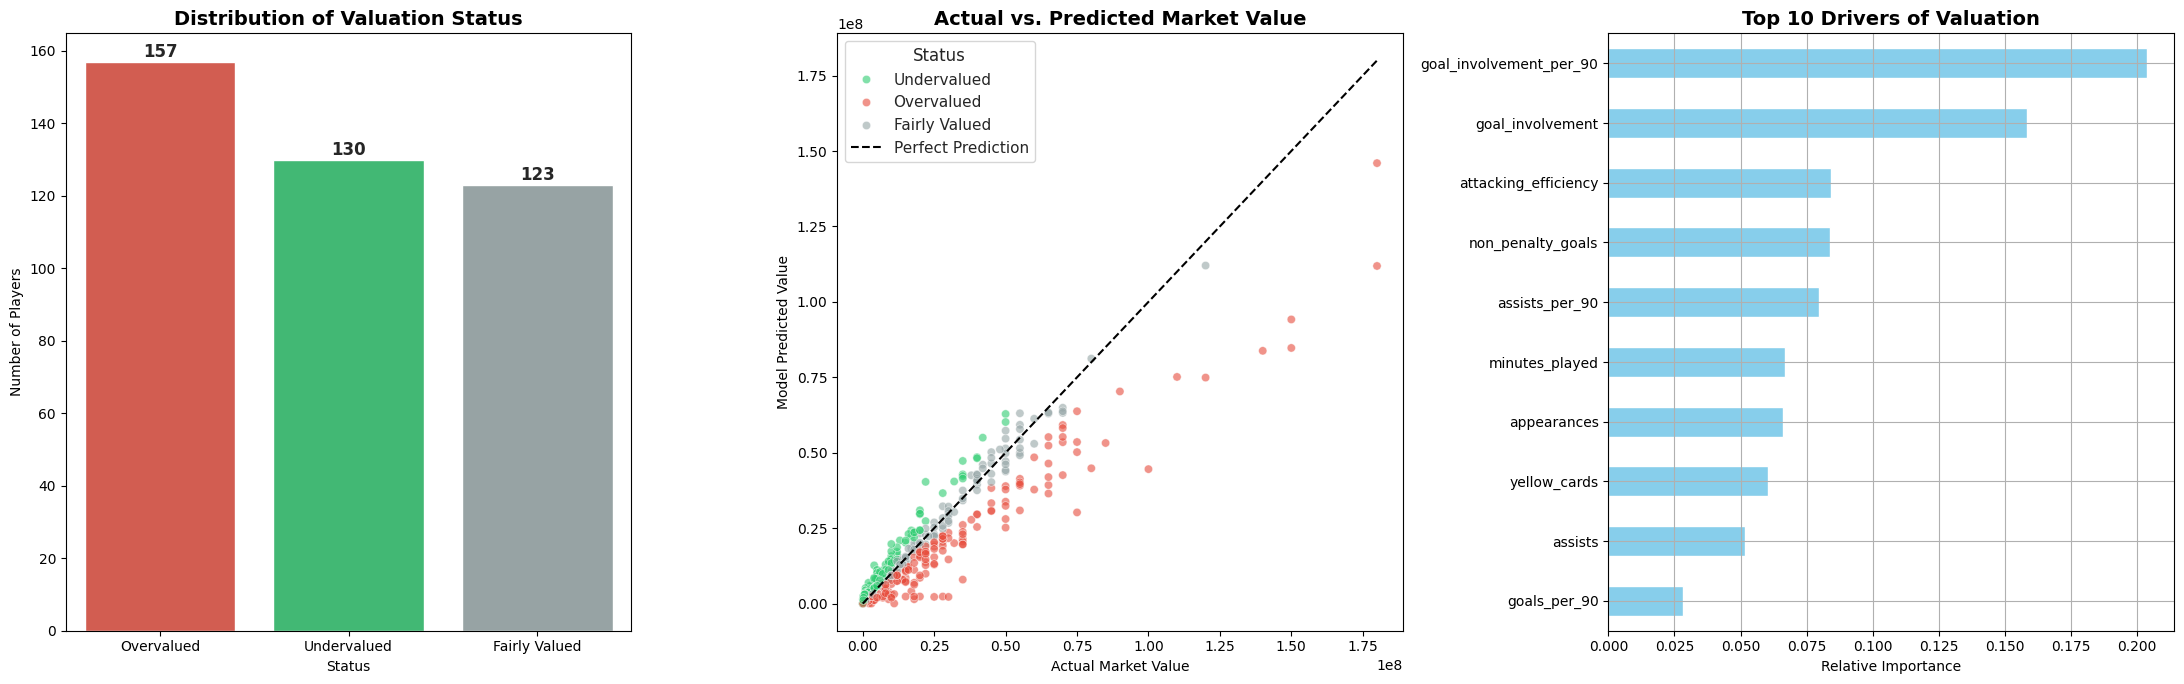

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
sns.set_theme(style="whitegrid")

#Bar chart
status_order = modeling_df['valuation_status'].value_counts().index
palette_colors = {"Overvalued": "#e74c3c", "Fairly Valued": "#95a5a6", "Undervalued": "#2ecc71"}

sns.countplot(data=modeling_df, x="valuation_status", order=status_order,
              palette=palette_colors, ax=axes[0])
axes[0].set_title("Distribution of Valuation Status", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Status")
axes[0].set_ylabel("Number of Players")

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontweight='bold')

#Scatter plot
sns.scatterplot(data=modeling_df, x="market_value", y="predicted_market_value",
                hue="valuation_status", palette=palette_colors, alpha=0.6, ax=axes[1])

max_val = max(modeling_df["market_value"].max(), modeling_df["predicted_market_value"].max())
axes[1].plot([0, max_val], [0, max_val], color='black', linestyle='--', label="Perfect Prediction")
axes[1].set_title("Actual vs. Predicted Market Value", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Actual Market Value")
axes[1].set_ylabel("Model Predicted Value")
axes[1].legend(title="Status", loc='upper left')

#Horizontal bar
importances = pd.Series(final_model.feature_importances_, index=X.columns)
top_10_features = importances.sort_values(ascending=True).tail(10)

top_10_features.plot(kind='barh', color='skyblue', ax=axes[2])
axes[2].set_title("Top 10 Drivers of Valuation", fontsize=14, fontweight='bold')
axes[2].set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()

### Ratio range summary

In [ ]:
status_order = ["Undervalued", "Fairly Valued", "Overvalued"]
ratio_range_summary = (
    modeling_df
    .dropna(subset=["valuation_ratio_range"])
    .groupby(["valuation_ratio_range", "valuation_status"], observed=True)
    .size()
    .rename("player_count")
    .reset_index()
)
ratio_range_summary["valuation_status"] = pd.Categorical(
    ratio_range_summary["valuation_status"],
    categories=status_order,
    ordered=True,
)
ratio_range_summary["range_total"] = ratio_range_summary.groupby("valuation_ratio_range")["player_count"].transform("sum")
ratio_range_summary["range_share"] = ratio_range_summary["player_count"] / ratio_range_summary["range_total"]
ratio_range_summary = ratio_range_summary.sort_values(["valuation_ratio_range", "valuation_status"])

display(ratio_range_summary.style.format({"range_share": "{:.1%}"}))

/tmp/ipykernel_4350/2786504197.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ratio_range_summary["range_total"] = ratio_range_summary.groupby("valuation_ratio_range")["player_count"].transform("sum")


,valuation_ratio_range,valuation_status,player_count,range_total,range_share
0,<=0.70,Undervalued,83,83,100.0%
1,0.70-0.85,Undervalued,47,47,100.0%
2,0.85-1.15 (Fair),Fairly Valued,123,123,100.0%
3,1.15-1.30,Overvalued,35,35,100.0%
4,>1.30,Overvalued,122,122,100.0%


## Validation error analysis

Use out-of-fold predictions from 5-fold cross-validation to inspect model error, calibration, and reliability on the full dataset.


### Error visualizations


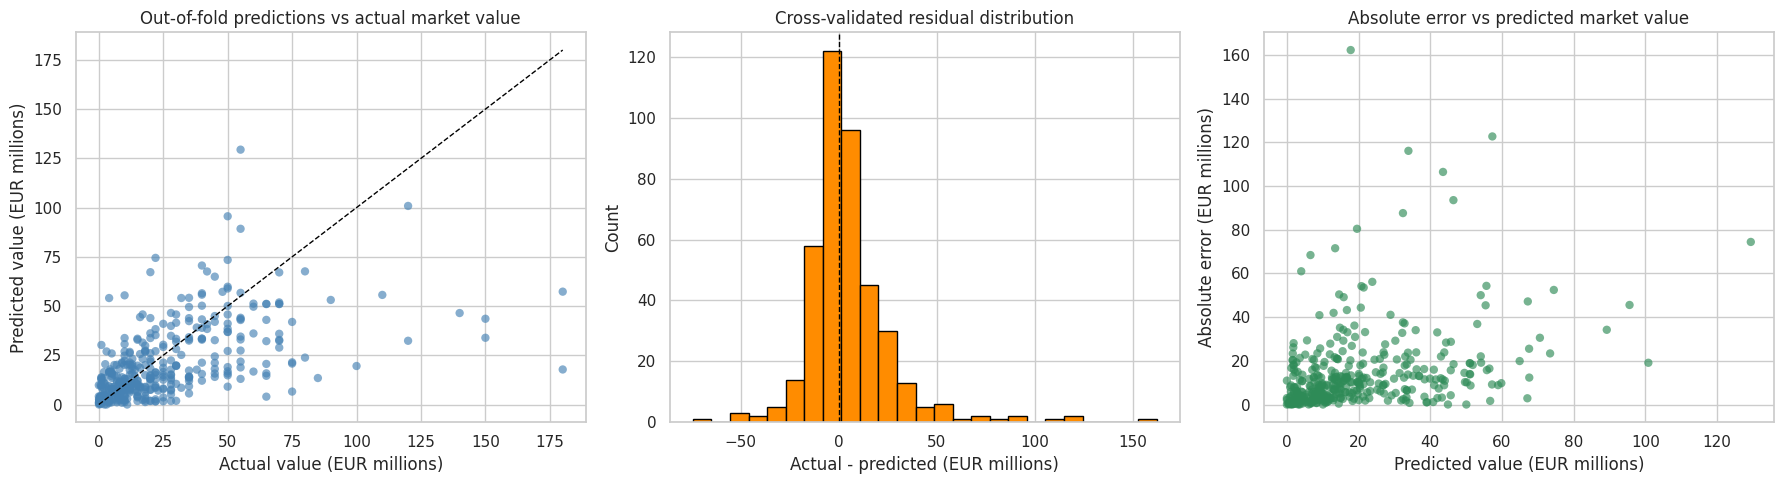

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    actual_market_values / 1_000_000,
    modeling_df["cv_predicted_market_value"] / 1_000_000,
    alpha=0.65,
    color="steelblue",
    edgecolors="none",
)
diag_min = 0
diag_max = max((actual_market_values.max() / 1_000_000), (modeling_df["cv_predicted_market_value"].max() / 1_000_000))
axes[0].plot([diag_min, diag_max], [diag_min, diag_max], linestyle="--", color="black", linewidth=1)
axes[0].set_title("Out-of-fold predictions vs actual market value")
axes[0].set_xlabel("Actual value (EUR millions)")
axes[0].set_ylabel("Predicted value (EUR millions)")

axes[1].hist(
    modeling_df["cv_residual_market_value"] / 1_000_000,
    bins=25,
    color="darkorange",
    edgecolor="black",
)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Cross-validated residual distribution")
axes[1].set_xlabel("Actual - predicted (EUR millions)")
axes[1].set_ylabel("Count")

abs_errors_m = np.abs(modeling_df["cv_residual_market_value"]) / 1_000_000
axes[2].scatter(
    modeling_df["cv_predicted_market_value"] / 1_000_000,
    abs_errors_m,
    alpha=0.65,
    color="seagreen",
    edgecolors="none",
)
axes[2].set_title("Absolute error vs predicted market value")
axes[2].set_xlabel("Predicted value (EUR millions)")
axes[2].set_ylabel("Absolute error (EUR millions)")

plt.tight_layout()
plt.show()


### Error analysis takeaway

The validation error shows that predicted values are not highly precise for every player, which is expected given the limited feature set and market noise. However, high prediction precision is not the primary objective of this study. The model is used as a consistent benchmark to compare actual value against model-implied fair value, so the error analysis should be interpreted as a caution on confidence, not as a failure of the study design.


## Conclusion

Based on the predicted-vs-actual value comparison, the market values of Premier League attacking players are only partially justified by on-field performance. If market prices were fully justified by performance, most players would fall in the fair-value ratio band; instead, the results show a substantial share outside that band, with both undervalued and overvalued cases. This indicates that performance explains part of valuation, but other factors beyond the selected performance metrics also materially shape market value.


## Challenge
- Limited number of performance metrices within the original dataset
- Low correlation of features and market value
- Extracting premier league attacker's data from large general dataset